# RAJUK Building-Approval Classifier — Balanced Random-Sampling Random Forest

A CUDA-accelerated Random Forest pipeline that classifies building images into
**negative / moderate / positive** approval levels.

Pipeline highlights:

- **Subject-level** train / validation / test split, so augmented copies of one
  original image never leak across splits.
- **Random balanced sampling**: an equal number of images per class is drawn
  *at random* (without replacement, reproducibly) for every training fit.
- CUDA ResNet50 (ImageNet) 2048-D embeddings; the tree ensembles run on CPU.
- Random Forest + Extra Trees combined by validation-selected soft voting.
- A **moderate-class emphasis step** that tunes the decision rule on validation to
  lift the hardest (middle) class's F1 without sacrificing overall macro-F1.
- Full classification report, confusion matrices, misclassified-image CSVs,
  bias-variance decomposition, feature importances, and a saved model artifact.

> Run the cells top to bottom. All outputs are written next to this notebook.

## 1. Imports, paths, and reproducibility

In [1]:
import gc
import re
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, log_loss,
    classification_report, confusion_matrix
)

warnings.filterwarnings('ignore', category=UserWarning)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

ROOT_HINT = Path(r'D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files')
root_candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent, ROOT_HINT]
PROJECT_ROOT = next(
    (path.resolve() for path in root_candidates
     if (path / 'Augmented_raw_data').exists() and (path / 'raw_data').exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate the project root containing raw_data and Augmented_raw_data.')

AUGMENTED_DIR = PROJECT_ROOT / 'Augmented_raw_data'
REAL_DIR = PROJECT_ROOT / 'raw_data' / 'final train image'
CSV_PATH = PROJECT_ROOT / 'Real ML_DataSet.csv'
XLSX_CANDIDATES = [PROJECT_ROOT / 'Real ML_DataSet.xlsx', PROJECT_ROOT / 'Rajuk_ML_DataSet.xlsx']
OUTPUT_DIR = PROJECT_ROOT / 'Random_Forest' / 'f4'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FEATURE_CACHE_DIR = OUTPUT_DIR / 'feature_cache'
FEATURE_CACHE_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ['negative', 'moderate', 'positive']
MODERATE_INDEX = CLASS_NAMES.index('moderate')
ALLOWED_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}
TEST_FRACTION = 0.20
VAL_FRACTION = 0.10
DEEP_BATCH_SIZE = 32
DATALOADER_WORKERS = 0
BACKBONE_NAME = 'resnet50'
MAX_TREES_PER_COMPONENT_FOR_BIAS_VARIANCE = 60

# Random balanced sampling: equal images per class, chosen at random per fit.
# MAX_PER_CLASS caps the count; the actual per-class size is min(MAX_PER_CLASS,
# smallest available class) so every class contributes the same amount.
MAX_PER_CLASS = 1500
# Moderate-class emphasis: multiply the moderate probability by one of these factors
# (chosen on validation) before predicting, to raise the middle class's F1.
MODERATE_FACTOR_GRID = [1.0, 1.1, 1.2, 1.35, 1.5, 1.7, 1.9, 2.2, 2.5]
MACRO_F1_TOLERANCE = 0.02   # allowed macro-F1 give-back while boosting moderate

MODEL_PATH = OUTPUT_DIR / 'rajuk_random_forest.pkl'
TEST_MISCLASSIFIED_CSV = OUTPUT_DIR / 'misclassified_images_random_forest.csv'
VAL_MISCLASSIFIED_CSV = OUTPUT_DIR / 'val_misclassified_random_forest.csv'
BIAS_VARIANCE_PNG = OUTPUT_DIR / 'bias_variance_random_forest.png'

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Project root       : {PROJECT_ROOT}')
print(f'Feature device     : {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'CUDA GPU           : {torch.cuda.get_device_name(0)}')
    print(f'PyTorch CUDA build : {torch.version.cuda}')
else:
    print('CUDA was not detected; feature extraction will use CPU and will be slower.')
print(f'Backbone           : {BACKBONE_NAME} (frozen, ImageNet pretrained)')
print('Tree training      : CPU (all available cores through n_jobs=-1)')
print(f'Output directory   : {OUTPUT_DIR}')

Project root       : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files
Feature device     : cuda
CUDA GPU           : NVIDIA GeForce GTX 1650
PyTorch CUDA build : 12.4
Backbone           : resnet50 (frozen, ImageNet pretrained)
Tree training      : CPU (all available cores through n_jobs=-1)
Output directory   : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f4


## 2. Load labels and create a subject-level split

Every augmented version inherits the split of its original `imgNN` subject, so
near-duplicate images can never straddle the train / validation / test boundary.

In [2]:
def normalize_header(name):
    return ''.join(ch for ch in str(name).lower() if ch.isalnum())

def find_column(frame, *targets):
    normalized = {normalize_header(column): column for column in frame.columns}
    return next((normalized[target] for target in targets if target in normalized), None)

def normalize_level(value):
    if pd.isna(value):
        return None
    return {
        'n': 'negative', 'negative': 'negative',
        'm': 'moderate', 'moderate': 'moderate',
        'p': 'positive', 'positive': 'positive',
    }.get(str(value).strip().lower())

if CSV_PATH.exists():
    labels_df = pd.read_csv(CSV_PATH)
    label_source = CSV_PATH
else:
    label_source = next((path for path in XLSX_CANDIDATES if path.exists()), None)
    if label_source is None:
        raise FileNotFoundError('No CSV/XLSX label file was found.')
    labels_df = pd.read_excel(label_source)

level_column = find_column(labels_df, 'levelpositivemoderatenegative', 'level')
if level_column is None:
    raise ValueError(f'Could not find the level column. Columns: {list(labels_df.columns)}')

class_to_index = {name: index for index, name in enumerate(CLASS_NAMES)}
label_map = {}
for row_index, value in enumerate(labels_df[level_column].tolist(), start=1):
    level = normalize_level(value)
    if level is not None:
        label_map[row_index] = class_to_index[level]

def parse_image_index(stem):
    match = re.match(r'img(\d+)', stem.strip().lower())
    return int(match.group(1)) if match else None

def collect_records(directory):
    records, skipped = [], 0
    if not directory.exists():
        raise FileNotFoundError(directory)
    for path in sorted(directory.rglob('*')):
        if not (path.is_file() and path.suffix.lower() in ALLOWED_EXTS):
            continue
        image_id = parse_image_index(path.stem)
        if image_id is None or image_id not in label_map:
            skipped += 1
            continue
        records.append((path, label_map[image_id], image_id))
    return records, skipped

augmented_records, skipped_augmented = collect_records(AUGMENTED_DIR)
real_records, skipped_real = collect_records(REAL_DIR)
unique_ids = np.array(sorted({record[2] for record in real_records}))
unique_labels = np.array([label_map[image_id] for image_id in unique_ids])

trainval_ids, test_ids = train_test_split(
    unique_ids, test_size=TEST_FRACTION, random_state=SEED, stratify=unique_labels
)
trainval_labels = np.array([label_map[image_id] for image_id in trainval_ids])
train_ids, val_ids = train_test_split(
    trainval_ids,
    test_size=VAL_FRACTION / (1.0 - TEST_FRACTION),
    random_state=SEED,
    stratify=trainval_labels,
)
train_ids, val_ids, test_ids = set(train_ids), set(val_ids), set(test_ids)
all_records = augmented_records + real_records
train_records = [record for record in all_records if record[2] in train_ids]
val_records = [record for record in all_records if record[2] in val_ids]
test_records = [record for record in all_records if record[2] in test_ids]

assert train_ids.isdisjoint(val_ids | test_ids)
assert val_ids.isdisjoint(test_ids)

def record_distribution(name, records):
    counts = np.bincount([record[1] for record in records], minlength=len(CLASS_NAMES))
    print(f'\n{name}: {len(records):,} images from {len({r[2] for r in records}):,} subjects')
    for class_name, count in zip(CLASS_NAMES, counts):
        print(f'  {class_name:10s}: {count:,}')

print(f'Loaded labels    : {len(label_map):,} from {label_source.name}')
print(f'Augmented images : {len(augmented_records):,}')
print(f'Real images      : {len(real_records):,}')
print(f'Skipped files    : {skipped_augmented + skipped_real:,}')
record_distribution('Training pool', train_records)
record_distribution('Validation', val_records)
record_distribution('Test', test_records)

Loaded labels    : 372 from Real ML_DataSet.csv
Augmented images : 5,968
Real images      : 373
Skipped files    : 17

Training pool: 4,420 images from 259 subjects
  negative  : 2,720
  moderate  : 969
  positive  : 731

Validation: 646 images from 38 subjects
  negative  : 408
  moderate  : 136
  positive  : 102

Test: 1,275 images from 75 subjects
  negative  : 782
  moderate  : 289
  positive  : 204


## 3. Extract ResNet50 embeddings (cached)

The frozen backbone runs on CUDA with fp16 autocast; only the compact 2048-D
L2-normalized embeddings return to RAM, and they are cached under `feature_cache/`
so reruns skip the GPU pass entirely.

In [3]:
def build_backbone():
    weights = models.ResNet50_Weights.IMAGENET1K_V2
    net = models.resnet50(weights=weights)
    net.fc = torch.nn.Identity()
    net = net.to(DEVICE).eval()
    for parameter in net.parameters():
        parameter.requires_grad = False
    return net, weights.transforms()

resnet_backbone, image_transform = build_backbone()

class ImageRecordDataset(Dataset):
    def __init__(self, records):
        self.records = records
    def __len__(self):
        return len(self.records)
    def __getitem__(self, index):
        path, label, image_id = self.records[index]
        with Image.open(path) as image:
            tensor = image_transform(image.convert('RGB'))
        return tensor, label, image_id, str(path)

def _extract_embeddings(records, split_name):
    loader = DataLoader(
        ImageRecordDataset(records), batch_size=DEEP_BATCH_SIZE, shuffle=False,
        num_workers=DATALOADER_WORKERS, pin_memory=(DEVICE.type == 'cuda')
    )
    features, labels, groups, paths = [], [], [], []
    processed = 0
    with torch.inference_mode():
        for images, batch_labels, batch_groups, batch_paths in loader:
            images = images.to(DEVICE, non_blocking=True)
            if DEVICE.type == 'cuda':
                with torch.autocast(device_type='cuda', dtype=torch.float16):
                    embeddings = resnet_backbone(images)
            else:
                embeddings = resnet_backbone(images)
            embeddings = F.normalize(embeddings.float(), p=2, dim=1)
            features.append(embeddings.cpu().numpy().astype(np.float32))
            labels.append(batch_labels.numpy().astype(np.int64))
            groups.append(batch_groups.numpy().astype(np.int64))
            paths.extend(batch_paths)
            processed += len(images)
            print(f'  {split_name}: {processed:,}/{len(records):,}', end='\r')
    print()
    return (np.concatenate(features), np.concatenate(labels),
            np.concatenate(groups), np.asarray(paths, dtype=object))

def extract_embeddings(records, split_name):
    cache = FEATURE_CACHE_DIR / f'{BACKBONE_NAME}_{split_name}_{len(records)}.npz'
    if cache.exists():
        data = np.load(cache, allow_pickle=True)
        print(f'  {split_name}: loaded {len(data["y"]):,} cached embeddings')
        paths = [Path(p) for p in data['paths']]
        return data['X'], data['y'], data['groups'], paths
    X, y, groups, paths = _extract_embeddings(records, split_name)
    np.savez_compressed(cache, X=X, y=y, groups=groups,
                        paths=np.asarray([str(p) for p in paths], dtype=object))
    return X, y, groups, [Path(p) for p in paths]

X_train_pool, y_train_pool, train_pool_groups, train_pool_paths = extract_embeddings(train_records, 'train')
X_val, y_val, val_groups, val_paths = extract_embeddings(val_records, 'validation')
X_test, y_test, test_groups, test_paths = extract_embeddings(test_records, 'test')
print(f'Embedding shapes: train_pool={X_train_pool.shape}, val={X_val.shape}, test={X_test.shape}')

  train: 4,420/4,420
  validation: 646/646
  test: 1,275/1,275
Embedding shapes: train_pool=(4420, 2048), val=(646, 2048), test=(1275, 2048)


## 4. Random balanced sampling

For every fit we draw the **same number of images per class, chosen uniformly at
random without replacement** from the training pool. This removes the majority-class
bias (which otherwise buries the moderate class) while keeping the selection random
and reproducible via the seed.

In [4]:
def make_random_balanced(X, y, groups, paths, random_state, max_per_class=MAX_PER_CLASS):
    rng = np.random.default_rng(random_state)
    class_counts = np.bincount(y, minlength=len(CLASS_NAMES))
    per_class = int(min(max_per_class, class_counts.min()))
    if per_class < 1:
        raise ValueError('A class has no images available for sampling.')
    selected_parts = []
    for class_index in range(len(CLASS_NAMES)):
        candidates = np.flatnonzero(y == class_index)
        selected_parts.append(rng.choice(candidates, size=per_class, replace=False))
    selected = np.concatenate(selected_parts)
    rng.shuffle(selected)
    balanced_counts = np.bincount(y[selected], minlength=len(CLASS_NAMES))
    assert len(set(balanced_counts.tolist())) == 1, 'Sampling is not balanced.'
    return X[selected], y[selected], groups[selected], [paths[i] for i in selected], per_class

X_train, y_train, train_groups, train_paths, per_class_used = make_random_balanced(
    X_train_pool, y_train_pool, train_pool_groups, train_pool_paths, random_state=SEED
)

sample_table = pd.DataFrame({
    'class': CLASS_NAMES,
    'available_in_pool': np.bincount(y_train_pool, minlength=len(CLASS_NAMES)),
    'randomly_selected': np.bincount(y_train, minlength=len(CLASS_NAMES)),
})
display(sample_table)
print(f'Randomly selected {per_class_used:,} images per class '
      f'({per_class_used * len(CLASS_NAMES):,} total) for training.')

,class,available_in_pool,randomly_selected
0,negative,2720,731
1,moderate,969,731
2,positive,731,731


Randomly selected 731 images per class (2,193 total) for training.


## 5. Fit the tree ensemble and select the best blend

Random Forest is a bagging method; Extra Trees adds extra split randomness. Both are
fit on the balanced random sample and evaluated at the subject level on validation.
We keep the best of **RandomForest / ExtraTrees / equal blend** by macro-F1.

In [5]:
TREE_CANDIDATES = {
    'rf': dict(name='RandomForest', family='rf', n_estimators=600, max_depth=None,
               min_samples_leaf=1, max_features='sqrt'),
    'extra': dict(name='ExtraTrees', family='extra', n_estimators=600, max_depth=None,
                  min_samples_leaf=1, max_features='sqrt'),
}

def build_tree_model(config, random_state):
    common = dict(
        n_estimators=config['n_estimators'], max_depth=config['max_depth'],
        min_samples_leaf=config['min_samples_leaf'], max_features=config['max_features'],
        bootstrap=True, oob_score=True, class_weight='balanced_subsample',
        random_state=random_state, n_jobs=-1,
    )
    if config['family'] == 'rf':
        return RandomForestClassifier(criterion='entropy', **common)
    return ExtraTreesClassifier(criterion='entropy', **common)

def ensemble_predict_proba(component_models, weights, X):
    weights = np.asarray(weights, dtype=np.float64)
    weights = weights / weights.sum()
    return np.average(np.stack([model.predict_proba(X) for model in component_models]),
                      axis=0, weights=weights)

def aggregate_probabilities_by_subject(probabilities, labels, groups):
    rows = []
    for group in np.unique(groups):
        mask = groups == group
        rows.append((int(labels[mask][0]), probabilities[mask].mean(axis=0)))
    subject_labels = np.asarray([row[0] for row in rows], dtype=np.int64)
    subject_probabilities = np.stack([row[1] for row in rows])
    return subject_labels, subject_probabilities

def metric_row(labels, predictions, probabilities):
    return {
        'macro_f1': f1_score(labels, predictions, average='macro', zero_division=0),
        'moderate_f1': f1_score(labels, predictions, average=None,
                                labels=np.arange(len(CLASS_NAMES)), zero_division=0)[MODERATE_INDEX],
        'balanced_accuracy': balanced_accuracy_score(labels, predictions),
        'accuracy': accuracy_score(labels, predictions),
        'log_loss': log_loss(labels, probabilities, labels=np.arange(len(CLASS_NAMES))),
    }

base_models, base_val_proba = {}, {}
for key, config in TREE_CANDIDATES.items():
    print(f'Fitting {config["name"]} ...')
    model = build_tree_model(config, SEED + (0 if key == 'rf' else 1))
    model.fit(X_train, y_train)
    base_models[key] = model
    base_val_proba[key] = model.predict_proba(X_val)
    print(f'  OOB accuracy: {model.oob_score_:.4f}')

ensemble_options = {
    'RandomForest':        (['rf'],          np.array([1.0])),
    'ExtraTrees':          (['extra'],       np.array([1.0])),
    'RF+ET blend (50/50)': (['rf', 'extra'], np.array([0.5, 0.5])),
}

selection_rows = []
for label, (keys, weights) in ensemble_options.items():
    weights = weights / weights.sum()
    proba = np.average(np.stack([base_val_proba[k] for k in keys]), axis=0, weights=weights)
    subj_y, subj_proba = aggregate_probabilities_by_subject(proba, y_val, val_groups)
    row = {'ensemble': label, 'component_keys': keys, 'weights': weights}
    row.update(metric_row(subj_y, subj_proba.argmax(axis=1), subj_proba))
    selection_rows.append(row)

selection_df = pd.DataFrame(selection_rows).sort_values(
    ['macro_f1', 'moderate_f1', 'balanced_accuracy'], ascending=False
).reset_index(drop=True)
display(selection_df[['ensemble', 'macro_f1', 'moderate_f1', 'balanced_accuracy', 'accuracy', 'log_loss']])

best = selection_df.iloc[0]
selected_keys = list(best['component_keys'])
selected_weights = np.asarray(best['weights'], dtype=float)
selected_configs = [TREE_CANDIDATES[k] for k in selected_keys]
selection_models = [base_models[k] for k in selected_keys]
print(f'\nSelected ensemble : {best["ensemble"]}  weights={selected_weights}')

Fitting RandomForest ...
  OOB accuracy: 0.3251
Fitting ExtraTrees ...
  OOB accuracy: 0.3333


,ensemble,macro_f1,moderate_f1,balanced_accuracy,accuracy,log_loss
0,RandomForest,0.619048,0.0,0.666667,0.789474,1.080380
1,ExtraTrees,0.619048,0.0,0.666667,0.789474,1.086729
2,RF+ET blend (50/50),0.619048,0.0,0.666667,0.789474,1.083519



Selected ensemble : RandomForest  weights=[1.]


## 6. Emphasize the moderate class

The middle (moderate) class is the hardest to separate. We scale its predicted
probability by a factor chosen on validation: among all factors we keep those whose
macro-F1 stays within a small tolerance of the best, then pick the one that maximizes
**moderate F1**. Predictions everywhere use `argmax(probabilities * class_factors)`.

In [6]:
def factored_predict(probabilities, factors):
    scaled = probabilities * np.asarray(factors, dtype=np.float64)
    scaled = scaled / scaled.sum(axis=1, keepdims=True)
    return scaled.argmax(axis=1)

val_probabilities = ensemble_predict_proba(selection_models, selected_weights, X_val)
val_subject_y, val_subject_proba = aggregate_probabilities_by_subject(
    val_probabilities, y_val, val_groups
)

tuning_rows = []
for factor in MODERATE_FACTOR_GRID:
    factors = np.ones(len(CLASS_NAMES)); factors[MODERATE_INDEX] = factor
    predictions = factored_predict(val_subject_proba, factors)
    tuning_rows.append({
        'moderate_factor': factor,
        'macro_f1': f1_score(val_subject_y, predictions, average='macro', zero_division=0),
        'moderate_f1': f1_score(val_subject_y, predictions, average=None,
                                labels=np.arange(len(CLASS_NAMES)), zero_division=0)[MODERATE_INDEX],
        'balanced_accuracy': balanced_accuracy_score(val_subject_y, predictions),
        'accuracy': accuracy_score(val_subject_y, predictions),
    })
tuning_df = pd.DataFrame(tuning_rows)
display(tuning_df)

best_macro = tuning_df['macro_f1'].max()
eligible = tuning_df[tuning_df['macro_f1'] >= best_macro - MACRO_F1_TOLERANCE]
chosen = eligible.sort_values(['moderate_f1', 'macro_f1'], ascending=False).iloc[0]
moderate_factor = float(chosen['moderate_factor'])
class_prior_factors = np.ones(len(CLASS_NAMES)); class_prior_factors[MODERATE_INDEX] = moderate_factor

baseline = tuning_df[tuning_df['moderate_factor'] == 1.0].iloc[0]
print(f'Chosen moderate factor : {moderate_factor}')
print(f'Validation moderate F1 : {baseline["moderate_f1"]:.4f} -> {chosen["moderate_f1"]:.4f}')
print(f'Validation macro F1    : {baseline["macro_f1"]:.4f} -> {chosen["macro_f1"]:.4f}')

# Cache individual-tree validation predictions (trees trained on the balanced sample)
# for the later bias-variance graph, then release the selection models.
bias_member_probabilities, bias_member_weights = [], []
for model, weight in zip(selection_models, selected_weights):
    if weight <= 0:
        continue
    tree_count = min(MAX_TREES_PER_COMPONENT_FOR_BIAS_VARIANCE, len(model.estimators_))
    tree_indices = np.linspace(0, len(model.estimators_) - 1, tree_count, dtype=int)
    for tree_index in tree_indices:
        tree = model.estimators_[tree_index]
        raw = tree.predict_proba(X_val)
        aligned = np.zeros((len(X_val), len(CLASS_NAMES)), dtype=np.float64)
        for column, class_index in enumerate(tree.classes_.astype(int)):
            aligned[:, class_index] = raw[:, column]
        bias_member_probabilities.append(aligned)
        bias_member_weights.append(float(weight) / tree_count)
bias_member_probabilities = np.stack(bias_member_probabilities)
bias_member_weights = np.asarray(bias_member_weights, dtype=np.float64)
bias_member_weights /= bias_member_weights.sum()

val_predictions = factored_predict(val_probabilities, class_prior_factors)
del base_models, selection_models, base_val_proba
gc.collect()

,moderate_factor,macro_f1,moderate_f1,balanced_accuracy,accuracy
0,1.00,0.619048,0.000000,0.666667,0.789474
1,1.10,0.466667,0.400000,0.666667,0.368421
2,1.20,0.115942,0.347826,0.333333,0.210526
3,1.35,0.115942,0.347826,0.333333,0.210526
4,1.50,0.115942,0.347826,0.333333,0.210526
5,1.70,0.115942,0.347826,0.333333,0.210526
6,1.90,0.115942,0.347826,0.333333,0.210526
7,2.20,0.115942,0.347826,0.333333,0.210526
8,2.50,0.115942,0.347826,0.333333,0.210526


Chosen moderate factor : 1.0
Validation moderate F1 : 0.0000 -> 0.0000
Validation macro F1    : 0.6190 -> 0.6190


48

## 7. Final refit and test evaluation

Training and validation pools are combined, resampled with the same random balanced
scheme (fresh seed), and the selected component(s) are refit once. The moderate
emphasis factor chosen above is applied to every prediction.

In [7]:
X_trainval_pool = np.vstack([X_train_pool, X_val])
y_trainval_pool = np.concatenate([y_train_pool, y_val])
trainval_pool_groups = np.concatenate([train_pool_groups, val_groups])
trainval_pool_paths = list(train_pool_paths) + list(val_paths)

X_trainval, y_trainval, trainval_groups, trainval_paths, _ = make_random_balanced(
    X_trainval_pool, y_trainval_pool, trainval_pool_groups, trainval_pool_paths,
    random_state=SEED + 1000
)

final_models = []
for model_index, config in enumerate(selected_configs):
    print(f'Final fit: {config["name"]}')
    model = build_tree_model(config, SEED + 2000 + model_index)
    model.fit(X_trainval, y_trainval)
    final_models.append(model)

train_probabilities = ensemble_predict_proba(final_models, selected_weights, X_trainval)
train_predictions = factored_predict(train_probabilities, class_prior_factors)
test_probabilities = ensemble_predict_proba(final_models, selected_weights, X_test)
test_predictions = factored_predict(test_probabilities, class_prior_factors)

test_accuracy = accuracy_score(y_test, test_predictions)
test_balanced_accuracy = balanced_accuracy_score(y_test, test_predictions)
test_macro_f1 = f1_score(y_test, test_predictions, average='macro', zero_division=0)
test_weighted_f1 = f1_score(y_test, test_predictions, average='weighted', zero_division=0)
per_class_f1 = f1_score(y_test, test_predictions, average=None,
                        labels=np.arange(len(CLASS_NAMES)), zero_division=0)
test_moderate_f1 = per_class_f1[MODERATE_INDEX]
test_log_loss = log_loss(y_test, test_probabilities, labels=np.arange(len(CLASS_NAMES)))

test_subject_y, test_subject_probabilities = aggregate_probabilities_by_subject(
    test_probabilities, y_test, test_groups
)
test_subject_predictions = factored_predict(test_subject_probabilities, class_prior_factors)
test_subject_metrics = metric_row(test_subject_y, test_subject_predictions, test_subject_probabilities)

def full_metrics_table(labels, predictions):
    from sklearn.metrics import precision_recall_fscore_support
    precision, recall, f1, support = precision_recall_fscore_support(
        labels, predictions, labels=np.arange(len(CLASS_NAMES)), zero_division=0)
    rows = []
    for class_index, class_name in enumerate(CLASS_NAMES):
        rows.append({'class': class_name, 'precision': precision[class_index],
                     'recall': recall[class_index], 'f1': f1[class_index],
                     'support': int(support[class_index])})
    for avg_name in ('macro', 'weighted'):
        p, r, f, _ = precision_recall_fscore_support(
            labels, predictions, labels=np.arange(len(CLASS_NAMES)),
            average=avg_name, zero_division=0)
        rows.append({'class': f'{avg_name} avg', 'precision': p, 'recall': r,
                     'f1': f, 'support': int(len(labels))})
    rows.append({'class': 'accuracy', 'precision': np.nan, 'recall': np.nan,
                 'f1': accuracy_score(labels, predictions), 'support': int(len(labels))})
    return pd.DataFrame(rows).round(4)

print('=' * 66)
print('  FULL TEST RESULT  (image level, all classes)')
print('=' * 66)
test_full_table = full_metrics_table(y_test, test_predictions)
display(test_full_table)

print('=' * 66)
print('  FULL TEST RESULT  (subject level, all classes)')
print('=' * 66)
subject_full_table = full_metrics_table(test_subject_y, test_subject_predictions)
display(subject_full_table)

print('SUMMARY')
print('-' * 60)
print(f'Image accuracy          : {test_accuracy:.4f}')
print(f'Image balanced accuracy : {test_balanced_accuracy:.4f}')
print(f'Image macro-F1          : {test_macro_f1:.4f}')
print(f'Image weighted-F1       : {test_weighted_f1:.4f}')
print(f'Image log loss          : {test_log_loss:.4f}')
for class_name, score in zip(CLASS_NAMES, per_class_f1):
    print(f'  F1[{class_name:8s}]        : {score:.4f}')
print(f'Subject accuracy        : {test_subject_metrics["accuracy"]:.4f}')
print(f'Subject macro-F1        : {test_subject_metrics["macro_f1"]:.4f}')

test_full_table.to_csv(OUTPUT_DIR / 'full_test_result_image_level.csv', index=False)
subject_full_table.to_csv(OUTPUT_DIR / 'full_test_result_subject_level.csv', index=False)

Final fit: RandomForest
  FULL TEST RESULT  (image level, all classes)


,class,precision,recall,f1,support
0,negative,0.0000,0.0000,0.0000,782
1,moderate,0.2316,1.0000,0.3761,289
2,positive,0.4444,0.0588,0.1039,204
3,macro avg,0.2253,0.3529,0.1600,1275
4,weighted avg,0.1236,0.2361,0.1019,1275
5,accuracy,NaN,NaN,0.2361,1275


  FULL TEST RESULT  (subject level, all classes)


,class,precision,recall,f1,support
0,negative,0.0000,0.0000,0.0000,46
1,moderate,0.3542,1.0000,0.5231,17
2,positive,0.4444,1.0000,0.6154,12
3,macro avg,0.2662,0.6667,0.3795,75
4,weighted avg,0.1514,0.3867,0.2170,75
5,accuracy,NaN,NaN,0.3867,75


SUMMARY
------------------------------------------------------------
Image accuracy          : 0.2361
Image balanced accuracy : 0.3529
Image macro-F1          : 0.1600
Image weighted-F1       : 0.1019
Image log loss          : 1.4973
  F1[negative]        : 0.0000
  F1[moderate]        : 0.3761
  F1[positive]        : 0.1039
Subject accuracy        : 0.3867
Subject macro-F1        : 0.3795


## 8. Classification report, confusion matrices, and error report

Test Set - Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00       782
    moderate       0.23      1.00      0.38       289
    positive       0.44      0.06      0.10       204

    accuracy                           0.24      1275
   macro avg       0.23      0.35      0.16      1275
weighted avg       0.12      0.24      0.10      1275



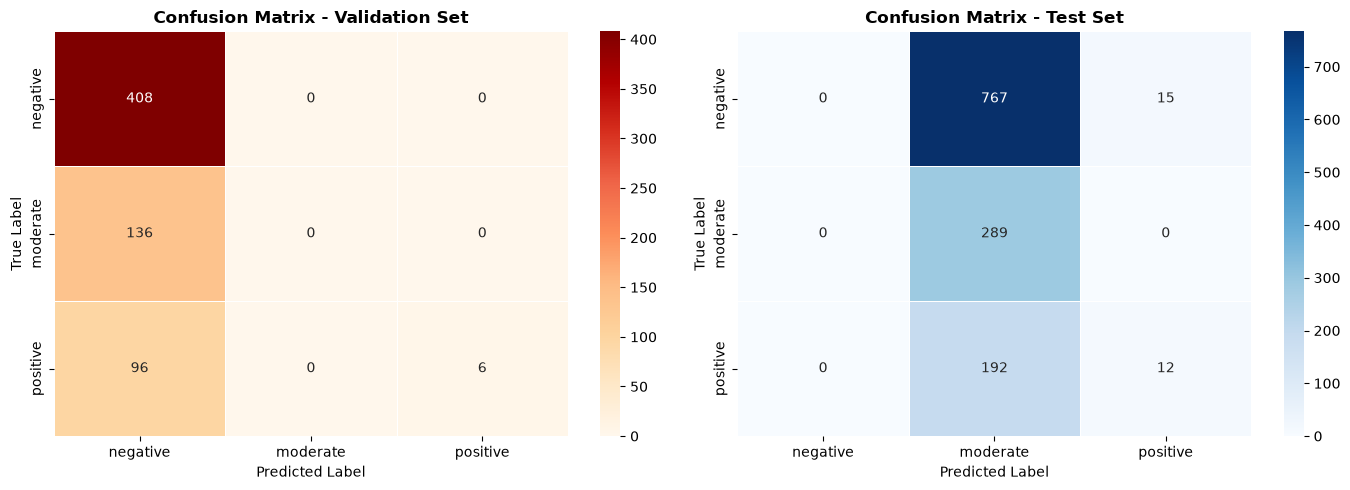

  FINAL ERROR REPORT - balanced random-sampling tree ensemble
  Split          Samples         Loss     Accuracy        Error
  --------------------------------------------------------------------
  Training         2,499       1.0942      33.73%       66.27%
  Validation         646       1.0876      64.09%       35.91%
  Test             1,275       1.4973      23.61%       76.39%


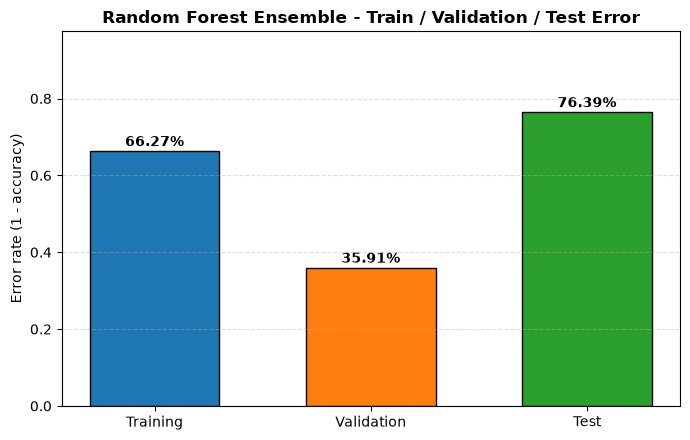

Classification CSV : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f4\test_classification_report_random_forest.csv
Confusion plot     : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f4\confusion_matrices_random_forest.png
Error report CSV   : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f4\final_error_report_random_forest.csv


In [8]:
print('Test Set - Classification Report')
print('-' * 60)
print(classification_report(
    y_test, test_predictions, labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES, zero_division=0
))

classification_report_df = pd.DataFrame(classification_report(
    y_test, test_predictions, labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES, zero_division=0, output_dict=True
)).T
classification_report_path = OUTPUT_DIR / 'test_classification_report_random_forest.csv'
classification_report_df.to_csv(classification_report_path)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, predictions, labels, title, colour_map in [
    (axes[0], val_predictions, y_val, 'Confusion Matrix - Validation Set', 'OrRd'),
    (axes[1], test_predictions, y_test, 'Confusion Matrix - Test Set', 'Blues'),
]:
    matrix = confusion_matrix(labels, predictions, labels=np.arange(len(CLASS_NAMES)))
    sns.heatmap(matrix, annot=True, fmt='d', cmap=colour_map,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=0.5, ax=ax)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
plt.tight_layout()
confusion_path = OUTPUT_DIR / 'confusion_matrices_random_forest.png'
plt.savefig(confusion_path, dpi=150, bbox_inches='tight')
plt.show()

train_loss = log_loss(y_trainval, train_probabilities, labels=np.arange(len(CLASS_NAMES)))
train_accuracy = accuracy_score(y_trainval, train_predictions)
val_loss = log_loss(y_val, val_probabilities, labels=np.arange(len(CLASS_NAMES)))
val_accuracy = accuracy_score(y_val, val_predictions)
report_rows = [
    ('Training', len(y_trainval), train_loss, train_accuracy, 1 - train_accuracy),
    ('Validation', len(y_val), val_loss, val_accuracy, 1 - val_accuracy),
    ('Test', len(y_test), test_log_loss, test_accuracy, 1 - test_accuracy),
]

print('=' * 74)
print('  FINAL ERROR REPORT - balanced random-sampling tree ensemble')
print('=' * 74)
print(f'  {"Split":<12}{"Samples":>10}{"Loss":>13}{"Accuracy":>13}{"Error":>13}')
print('  ' + '-' * 68)
for split_name, sample_count, loss_value, accuracy_value, error_value in report_rows:
    print(f'  {split_name:<12}{sample_count:>10,}{loss_value:>13.4f}'
          f'{accuracy_value:>12.2%}{error_value:>13.2%}')
print('=' * 74)

final_error_df = pd.DataFrame(report_rows, columns=['split', 'samples', 'loss', 'accuracy', 'error'])
final_error_csv = OUTPUT_DIR / 'final_error_report_random_forest.csv'
final_error_df.to_csv(final_error_csv, index=False)

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(final_error_df['split'], final_error_df['error'],
              color=['#1f77b4', '#ff7f0e', '#2ca02c'], edgecolor='black', width=0.6)
for bar, error_rate in zip(bars, final_error_df['error']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{error_rate:.2%}', ha='center', va='bottom', fontweight='bold')
ax.set_ylabel('Error rate (1 - accuracy)')
ax.set_title('Random Forest Ensemble - Train / Validation / Test Error', fontweight='bold')
ax.set_ylim(0, max(final_error_df['error']) * 1.25 + 0.02)
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
final_error_png = OUTPUT_DIR / 'final_error_report_random_forest.png'
plt.savefig(final_error_png, dpi=150, bbox_inches='tight')
plt.show()

print(f'Classification CSV : {classification_report_path}')
print(f'Confusion plot     : {confusion_path}')
print(f'Error report CSV   : {final_error_csv}')

## 9. Misclassified image reports

Both CSV files contain the image name, full path, subject ID, true/predicted labels,
confidence, and all class probabilities.

Validation misclassified: 232/646
Test misclassified      : 974/1,275


,split,split_index,image_name,image_path,image_id,image_type,true_label,predicted_label,error_type,confidence,probability_negative,probability_moderate,probability_positive
0,test,272,img108_autocontrast.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,108,augmented,negative,moderate,negative -> moderate,0.334655,0.334655,0.334655,0.33069
1,test,273,img108_brightness_down.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,108,augmented,negative,moderate,negative -> moderate,0.334655,0.334655,0.334655,0.33069
2,test,274,img108_brightness_up.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,108,augmented,negative,moderate,negative -> moderate,0.334655,0.334655,0.334655,0.33069
3,test,275,img108_color_down.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,108,augmented,negative,moderate,negative -> moderate,0.334655,0.334655,0.334655,0.33069
4,test,276,img108_color_up.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,108,augmented,negative,moderate,negative -> moderate,0.334655,0.334655,0.334655,0.33069
5,test,277,img108_contrast_down.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,108,augmented,negative,moderate,negative -> moderate,0.334655,0.334655,0.334655,0.33069
6,test,278,img108_contrast_up.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,108,augmented,negative,moderate,negative -> moderate,0.334655,0.334655,0.334655,0.33069
7,test,279,img108_edge_enhance.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,108,augmented,negative,moderate,negative -> moderate,0.334655,0.334655,0.334655,0.33069
8,test,280,img108_equalize.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,108,augmented,negative,moderate,negative -> moderate,0.334655,0.334655,0.334655,0.33069
9,test,281,img108_gaussian_blur.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,108,augmented,negative,moderate,negative -> moderate,0.334655,0.334655,0.334655,0.33069


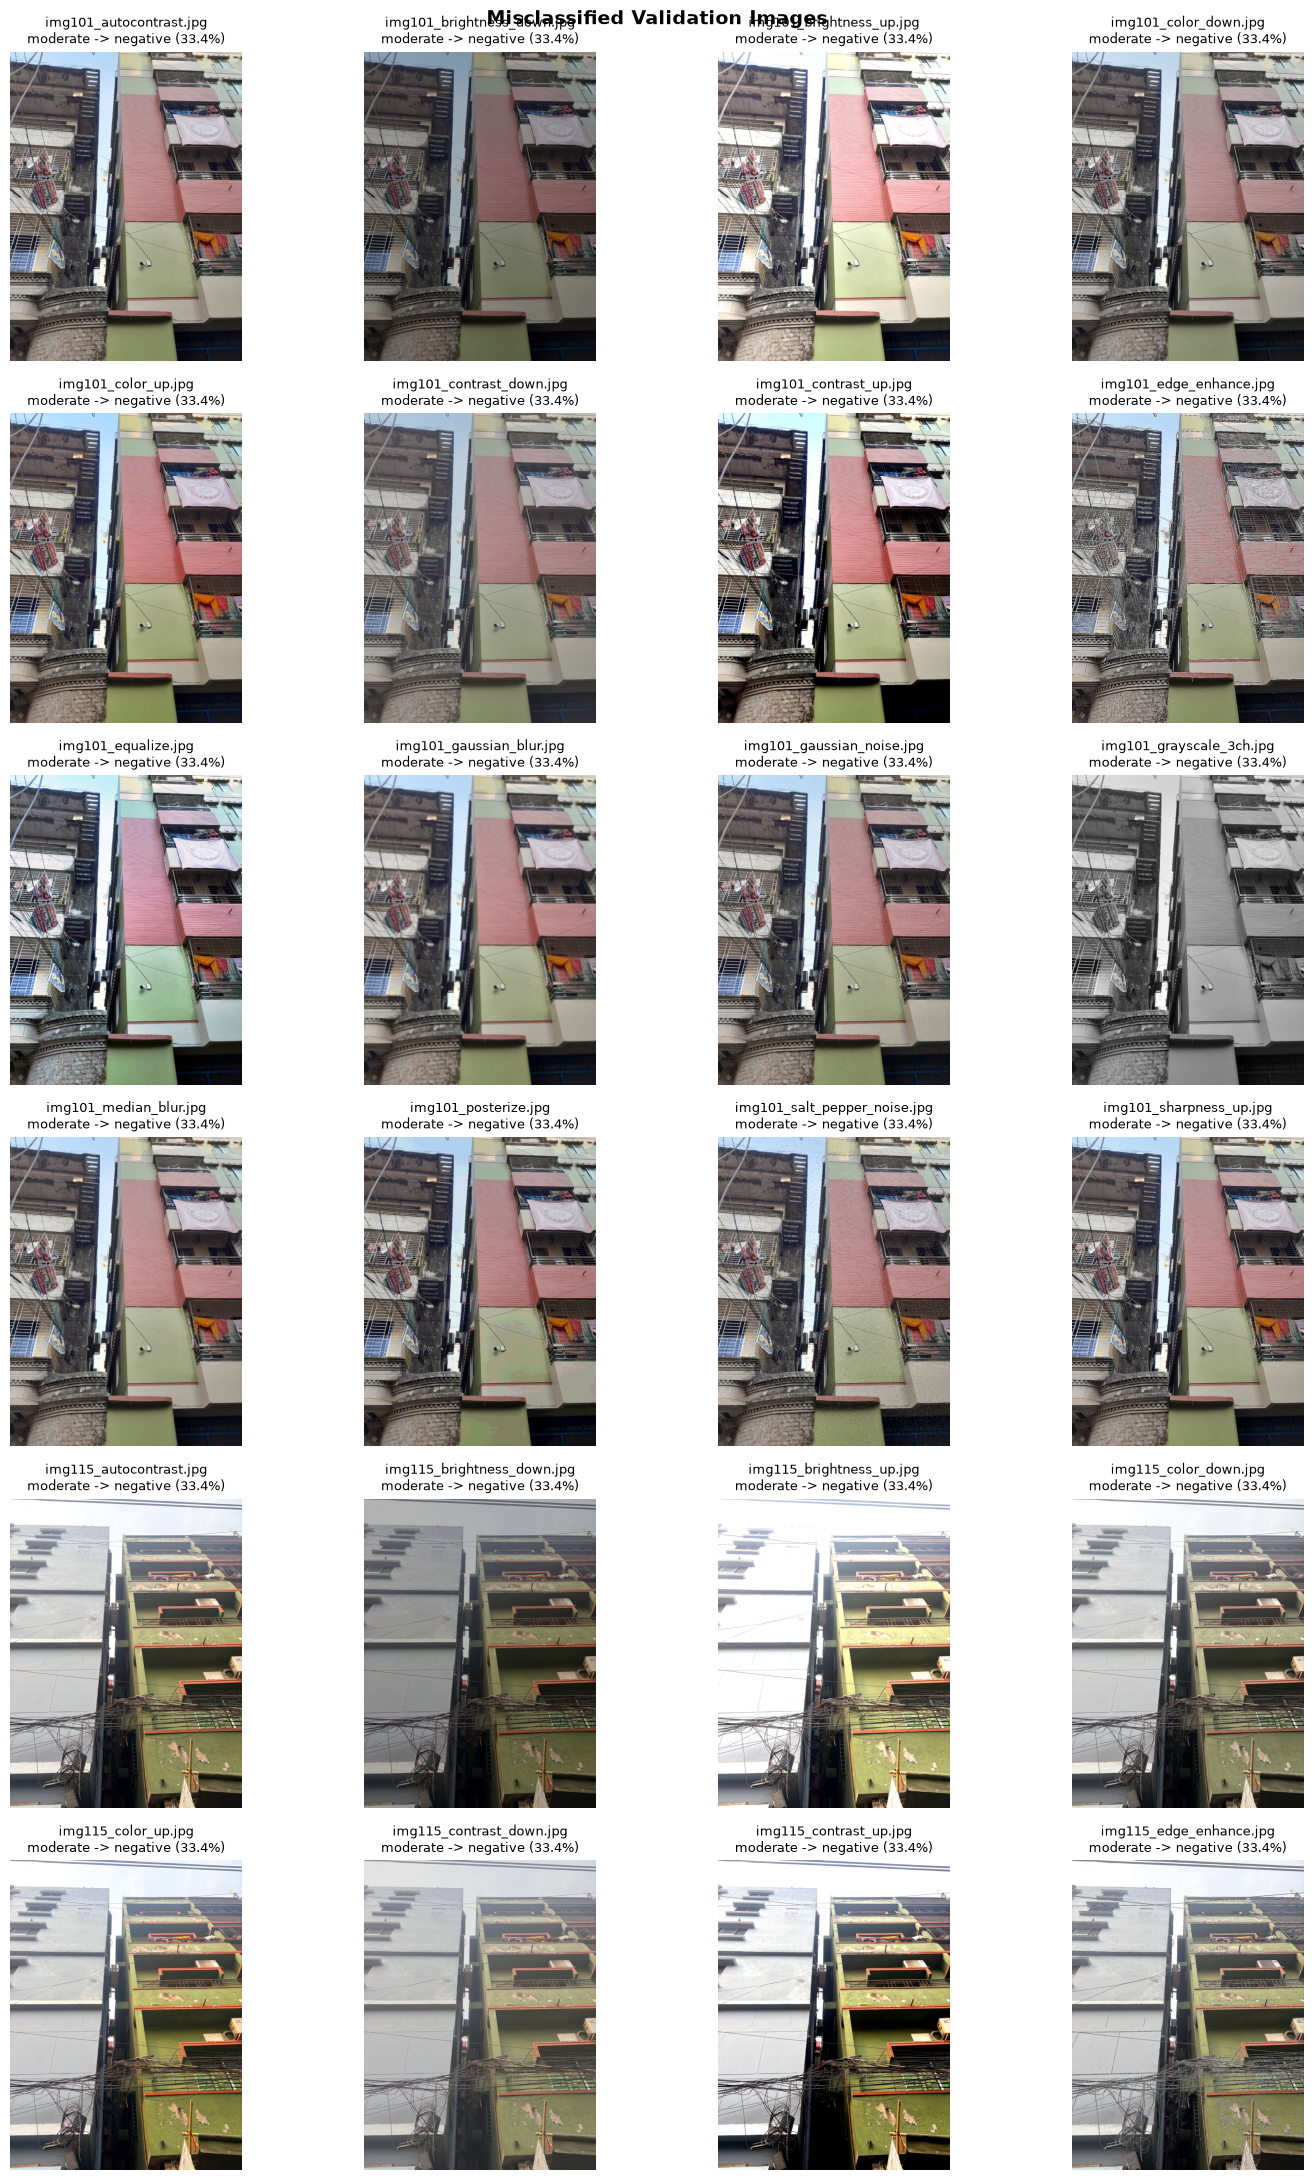

In [9]:
augmented_root = AUGMENTED_DIR.resolve()

def is_augmented_path(path):
    try:
        return Path(path).resolve().is_relative_to(augmented_root)
    except Exception:
        return 'aug' in str(path).lower()

def build_misclassified_table(labels, predictions, probabilities, groups, paths, split_name):
    indices = np.flatnonzero(predictions != labels)
    rows = []
    for index in indices:
        path = Path(paths[index])
        image_type = 'augmented' if is_augmented_path(path) else 'real'
        row = {
            'split': split_name, 'split_index': int(index), 'image_name': path.name,
            'image_path': str(path), 'image_id': int(groups[index]), 'image_type': image_type,
            'true_label': CLASS_NAMES[int(labels[index])],
            'predicted_label': CLASS_NAMES[int(predictions[index])],
            'error_type': f'{CLASS_NAMES[int(labels[index])]} -> {CLASS_NAMES[int(predictions[index])]}',
            'confidence': float(probabilities[index, predictions[index]]),
        }
        for class_index, class_name in enumerate(CLASS_NAMES):
            row[f'probability_{class_name}'] = float(probabilities[index, class_index])
        rows.append(row)
    return pd.DataFrame(rows)

val_misclassified_df = build_misclassified_table(
    y_val, val_predictions, val_probabilities, val_groups, val_paths, 'validation')
test_misclassified_df = build_misclassified_table(
    y_test, test_predictions, test_probabilities, test_groups, test_paths, 'test')
val_misclassified_df.to_csv(VAL_MISCLASSIFIED_CSV, index=False)
test_misclassified_df.to_csv(TEST_MISCLASSIFIED_CSV, index=False)

print(f'Validation misclassified: {len(val_misclassified_df):,}/{len(y_val):,}')
print(f'Test misclassified      : {len(test_misclassified_df):,}/{len(y_test):,}')
display(test_misclassified_df.head(20))

MAX_ERRORS_TO_DISPLAY = 24
display_rows = val_misclassified_df.head(MAX_ERRORS_TO_DISPLAY)
if len(display_rows):
    columns = 4
    rows = int(np.ceil(len(display_rows) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(15, 3.7 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (_, row) in zip(axes, display_rows.iterrows()):
        with Image.open(row['image_path']) as image:
            ax.imshow(image.convert('RGB'))
        ax.set_title(f"{row['image_name']}\n{row['true_label']} -> {row['predicted_label']} "
                     f"({row['confidence']:.1%})", fontsize=9)
        ax.axis('off')
    for ax in axes[len(display_rows):]:
        ax.axis('off')
    fig.suptitle('Misclassified Validation Images', fontsize=14, fontweight='bold')
    plt.tight_layout()
    validation_grid_path = OUTPUT_DIR / 'val_misclassified_grid_random_forest.png'
    plt.savefig(validation_grid_path, dpi=130, bbox_inches='tight')
    plt.show()

## 10. Bias-variance analysis

Individual trees (trained on the balanced random sample) are treated as ensemble
members and their validation probability predictions are decomposed into squared
bias and variance.

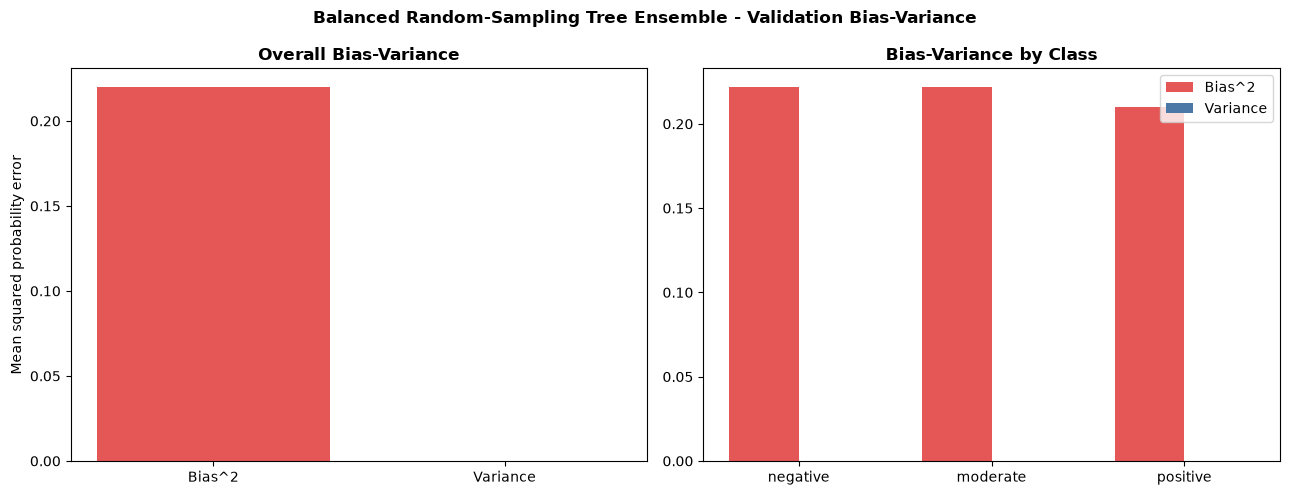

Bias^2: 0.219941 | Variance: 0.000034


In [10]:
member_probabilities = bias_member_probabilities
member_weights = bias_member_weights
mean_probabilities = np.average(member_probabilities, axis=0, weights=member_weights)
one_hot = np.eye(len(CLASS_NAMES))[y_val]
bias_squared_samples = np.mean((mean_probabilities - one_hot) ** 2, axis=1)
per_member_squared_distance = np.mean(
    (member_probabilities - mean_probabilities[None, :, :]) ** 2, axis=2)
variance_samples = np.average(per_member_squared_distance, axis=0, weights=member_weights)

overall_bias_squared = float(bias_squared_samples.mean())
overall_variance = float(variance_samples.mean())
class_bias = [bias_squared_samples[y_val == index].mean() for index in range(len(CLASS_NAMES))]
class_variance = [variance_samples[y_val == index].mean() for index in range(len(CLASS_NAMES))]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(['Bias^2', 'Variance'], [overall_bias_squared, overall_variance],
            color=['#e45756', '#4c78a8'])
axes[0].set_title('Overall Bias-Variance', fontweight='bold')
axes[0].set_ylabel('Mean squared probability error')

positions = np.arange(len(CLASS_NAMES))
width = 0.36
axes[1].bar(positions - width/2, class_bias, width, label='Bias^2', color='#e45756')
axes[1].bar(positions + width/2, class_variance, width, label='Variance', color='#4c78a8')
axes[1].set_xticks(positions)
axes[1].set_xticklabels(CLASS_NAMES)
axes[1].set_title('Bias-Variance by Class', fontweight='bold')
axes[1].legend()
fig.suptitle('Balanced Random-Sampling Tree Ensemble - Validation Bias-Variance', fontweight='bold')
plt.tight_layout()
plt.savefig(BIAS_VARIANCE_PNG, dpi=160, bbox_inches='tight')
plt.show()
print(f'Bias^2: {overall_bias_squared:.6f} | Variance: {overall_variance:.6f}')

## 11. Ensemble feature importance

,embedding_dimension,importance
0,resnet50_2021,0.005000
1,resnet50_558,0.005000
2,resnet50_648,0.005000
3,resnet50_1800,0.005000
4,resnet50_1793,0.005000
5,resnet50_939,0.005000
6,resnet50_1500,0.003333
7,resnet50_1503,0.003333
8,resnet50_720,0.003333
9,resnet50_214,0.003333


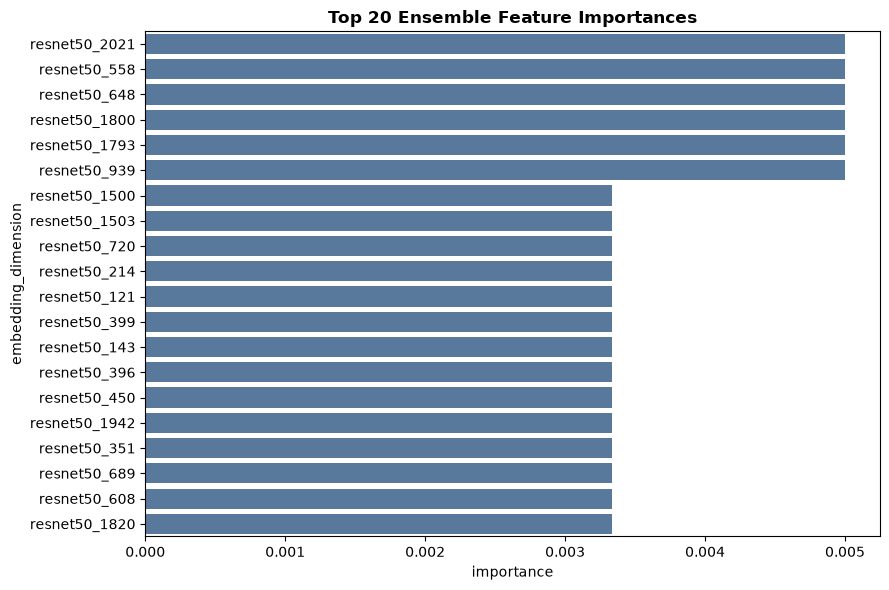

In [11]:
normalized_weights = np.asarray(selected_weights, dtype=float)
normalized_weights /= normalized_weights.sum()
ensemble_importance = np.average(
    np.stack([model.feature_importances_ for model in final_models]),
    axis=0, weights=normalized_weights)
top_indices = np.argsort(ensemble_importance)[-20:][::-1]
importance_df = pd.DataFrame({
    'embedding_dimension': [f'{BACKBONE_NAME}_{index}' for index in top_indices],
    'importance': ensemble_importance[top_indices],
})
display(importance_df)
plt.figure(figsize=(9, 6))
sns.barplot(data=importance_df, y='embedding_dimension', x='importance', color='#4c78a8')
plt.title('Top 20 Ensemble Feature Importances', fontweight='bold')
plt.tight_layout()
feature_importance_path = OUTPUT_DIR / 'feature_importance_random_forest.png'
plt.savefig(feature_importance_path, dpi=150, bbox_inches='tight')
plt.show()

## 12. Save the model and inference helper

In [12]:
artifact = {
    'component_models': final_models,
    'voting_weights': np.asarray(selected_weights),
    'class_prior_factors': class_prior_factors,
    'moderate_factor': moderate_factor,
    'selected_configs': selected_configs,
    'class_names': CLASS_NAMES,
    'backbone': BACKBONE_NAME,
    'feature_extractor': 'ImageNet pretrained ResNet50 (V2) frozen 2048-D L2-normalized embedding',
    'sampling': f'random balanced, {per_class_used} images per class without replacement',
    'label_source': str(label_source),
    'test_accuracy': float(test_accuracy),
    'test_balanced_accuracy': float(test_balanced_accuracy),
    'test_macro_f1': float(test_macro_f1),
    'test_moderate_f1': float(test_moderate_f1),
    'test_subject_metrics': test_subject_metrics,
}
with open(MODEL_PATH, 'wb') as file:
    pickle.dump(artifact, file)

print(f'Model saved to     : {MODEL_PATH}')
print(f'Test accuracy      : {test_accuracy:.4f}')
print(f'Test macro-F1      : {test_macro_f1:.4f}')
print(f'Test moderate-F1   : {test_moderate_f1:.4f}')

def load_artifact(model_path=MODEL_PATH):
    with open(model_path, 'rb') as file:
        return pickle.load(file)

def predict_image(image_path, trained_artifact):
    with Image.open(image_path) as image:
        tensor = image_transform(image.convert('RGB')).unsqueeze(0).to(DEVICE)
    with torch.inference_mode():
        if DEVICE.type == 'cuda':
            with torch.autocast(device_type='cuda', dtype=torch.float16):
                embedding = resnet_backbone(tensor)
        else:
            embedding = resnet_backbone(tensor)
        embedding = F.normalize(embedding.float(), p=2, dim=1).cpu().numpy()
    probabilities = ensemble_predict_proba(
        trained_artifact['component_models'], trained_artifact['voting_weights'], embedding)[0]
    factors = np.asarray(trained_artifact['class_prior_factors'], dtype=np.float64)
    scaled = probabilities * factors
    scaled = scaled / scaled.sum()
    predicted_index = int(np.argmax(scaled))
    return {
        'prediction': trained_artifact['class_names'][predicted_index],
        'confidence': float(probabilities[predicted_index]),
        'probabilities': dict(zip(trained_artifact['class_names'], probabilities.astype(float))),
    }

# Example:
# trained_artifact = load_artifact()
# print(predict_image(PROJECT_ROOT / 'new_image.jpg', trained_artifact))

Model saved to     : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f4\rajuk_random_forest.pkl
Test accuracy      : 0.2361
Test macro-F1      : 0.1600
Test moderate-F1   : 0.3761
